TH 5.1.
Dựng tam giác Pascal 10 hàng trong ma trận số nguyên 10×10 bằng slicing (mỗi hàng tính từ hàng trước bằng một phép cộng vector, không dùng vòng lặp lồng): Pi,j=Pi−1,j+Pi−1,j−1, Pi,0=1. In hàng 4 và hàng 9; kiểm tra (94)=126 và tổng hàng 9 bằng 2^9.

In [1]:
import numpy as np
P = np.zeros((10, 10), dtype=int)
P[:, 0] = 1
for i in range(1, 10):
    P[i, 1:i+1] = P[i-1, 0:i] + P[i-1, 1:i+1]
print("Hàng 4:", P[4, :5])
print("Hàng 9:", P[9, :10])
print("P[9,4] =", P[9, 4])
print("Tổng hàng 9:", np.sum(P[9, :10]))
print("2^9 =", 2**9)
print("\nMa trận Pascal:")
print(P)


Hàng 4: [1 4 6 4 1]
Hàng 9: [  1   9  36  84 126 126  84  36   9   1]
P[9,4] = 126
Tổng hàng 9: 512
2^9 = 512

Ma trận Pascal:
[[  1   0   0   0   0   0   0   0   0   0]
 [  1   1   0   0   0   0   0   0   0   0]
 [  1   2   1   0   0   0   0   0   0   0]
 [  1   3   3   1   0   0   0   0   0   0]
 [  1   4   6   4   1   0   0   0   0   0]
 [  1   5  10  10   5   1   0   0   0   0]
 [  1   6  15  20  15   6   1   0   0   0]
 [  1   7  21  35  35  21   7   1   0   0]
 [  1   8  28  56  70  56  28   8   1   0]
 [  1   9  36  84 126 126  84  36   9   1]]


TH 5.6.
Cho

```
A=[2 1 −1 0
   1 3 2 1
   0 −1 4 2
   3 0 1 5]
```


và véc tơ nghiệm biết trước x∗=(1,−1,2,3)⊤. Đặt b=Ax∗, giải lại hệ bằng np.linalg.solve, kiểm chứng bằng np.allclose. Sau đó thay hàng 4 của A bằng tổng hàng 1 và hàng 2 và ghi lại lỗi của solve.

In [3]:
import numpy as np
A = np.array([
    [2,  1, -1, 0],
    [1,  3,  2, 1],
    [0, -1,  4, 2],
    [3,  0,  1, 5]
], dtype=float)
x_true = np.array([1, -1, 2, 3], dtype=float)
b = A @ x_true
print("Ma trận A:")
print(A)
print("\nVéc tơ b:")
print(b)
x = np.linalg.solve(A, b)
print("\nNghiệm tìm được:")
print(x)
print("\nKiểm chứng:", np.allclose(A @ x, b))
print("So sánh với nghiệm ban đầu:", np.allclose(x, x_true))
A[3] = A[0] + A[1]
print("\nMa trận A sau khi thay hàng 4:")
print(A)
try:
    x_new = np.linalg.solve(A, b)
    print("Nghiệm mới:", x_new)
except np.linalg.LinAlgError as e:
    print("Lỗi của solve:", e)


Ma trận A:
[[ 2.  1. -1.  0.]
 [ 1.  3.  2.  1.]
 [ 0. -1.  4.  2.]
 [ 3.  0.  1.  5.]]

Véc tơ b:
[-1.  5. 15. 20.]

Nghiệm tìm được:
[ 1. -1.  2.  3.]

Kiểm chứng: True
So sánh với nghiệm ban đầu: True

Ma trận A sau khi thay hàng 4:
[[ 2.  1. -1.  0.]
 [ 1.  3.  2.  1.]
 [ 0. -1.  4.  2.]
 [ 3.  4.  1.  1.]]
Nghiệm mới: [ 8.40671930e+16 -2.40191980e+16  1.44115188e+17 -3.00239975e+17]


TH 5.7.
Đa thức bậc 3 đi qua bốn điểm (0,1), (1,0), (2,5), (3,22) là duy nhất. Tìm các hệ số c0,…,c3 của p(x)=c0+c1x+c2x^2+c3x^3 bằng cách giải hệ với ma trận Vandermonde (np.vander(x, increasing=True)), kiểm tra bằng allclose, rồi tính p(1,5).

In [4]:
import numpy as np
x = np.array([0, 1, 2, 3], dtype=float)
y = np.array([1, 0, 5, 22], dtype=float)
V = np.vander(x, increasing=True)
print("Ma trận Vandermonde:")
print(V)
c = np.linalg.solve(V, y)
print("\nCác hệ số đa thức:")
print("c0 =", c[0])
print("c1 =", c[1])
print("c2 =", c[2])
print("c3 =", c[3])
y_check = V @ c
print("\nGiá trị kiểm tra:", y_check)
print("Kết quả allclose:", np.allclose(y_check, y))
x_new = 1.5
p = c[0] + c[1]*x_new + c[2]*x_new**2 + c[3]*x_new**3
print("\np(1.5) =", p)


Ma trận Vandermonde:
[[ 1.  0.  0.  0.]
 [ 1.  1.  1.  1.]
 [ 1.  2.  4.  8.]
 [ 1.  3.  9. 27.]]

Các hệ số đa thức:
c0 = 1.0
c1 = -2.0
c2 = -0.0
c3 = 1.0

Giá trị kiểm tra: [ 1.  0.  5. 22.]
Kết quả allclose: True

p(1.5) = 1.375


TH 5.8.
Với ma trận ngẫu nhiên 500×500 (default_rng(0)) và véc tơ b ngẫu nhiên, giải Ax=b bằng solve và bằng inv(A) @ b. So sánh phần dư ∥Ax−b∥ và thời gian của hai cách; kiểm tra bằng assert cả hai nghiệm đều đạt phần dư rất nhỏ và giống nhau.

In [6]:
import numpy as np
import time
rng = np.random.default_rng(0)
A = rng.random((500, 500))
b = rng.random(500)

start = time.perf_counter()
x1 = np.linalg.solve(A, b)
time_solve = time.perf_counter() - start

start = time.perf_counter()
x2 = np.linalg.inv(A) @ b
time_inv = time.perf_counter() - start

r1 = np.linalg.norm(A @ x1 - b)
r2 = np.linalg.norm(A @ x2 - b)

print("Cách 1: np.linalg.solve():")
print("Phần dư:", r1)
print("Thời gian:", time_solve, "giây")

print("\nCách 2: np.linalg.inv(A) @ b:")
print("Phần dư:", r2)
print("Thời gian:", time_inv, "giây")

print("\nHai nghiệm giống nhau:", np.allclose(x1, x2))

assert r1 < 1e-8, "Nghiệm solve có phần dư quá lớn"
assert r2 < 1e-8, "Nghiệm inv có phần dư quá lớn"
assert np.allclose(x1, x2, rtol=1e-5, atol=1e-8)

print("\nTất cả kiểm tra đều thành công!")


Cách 1: np.linalg.solve():
Phần dư: 8.058540555394598e-13
Thời gian: 0.012750086000096417 giây

Cách 2: np.linalg.inv(A) @ b:
Phần dư: 2.3621299704879234e-12
Thời gian: 0.027510967999887725 giây

Hai nghiệm giống nhau: True

Tất cả kiểm tra đều thành công!


TH 6.2.
Viết chương trình nhập danh sách sinh viên (họ tên, mã sinh viên, ngày sinh dạng dd/mm/yyyy) từ bàn phím, dừng khi người dùng bỏ trống họ tên (vòng while True, Chương 2). Lưu vào một DataFrame, chuyển ngày sinh sang kiểu thời gian bằng pd.to_datetime(…, format="%d/%m/%Y"), tính cột Tuoi (số năm nguyên) từ ngày sinh đến mốc 01/01/2026 (dùng pd.Timestamp("2026-01-01"), chia số ngày cho 365,25 rồi lấy phần nguyên), ghi ra students.xlsx bằng to_excel (cần openpyxl) và đọc lại để kiểm tra. Dùng mốc cố định thay cho pd.Timestamp.now() để kết quả tái lập được.

In [7]:
import pandas as pd
students = []
while True:
    ho_ten = input("Nhập họ tên sinh viên (Enter để kết thúc): ")
    if ho_ten.strip() == "":
        break
    ma_sv = input("Nhập mã sinh viên: ")
    ngay_sinh = input("Nhập ngày sinh (dd/mm/yyyy): ")
    students.append({
        "HoTen": ho_ten,
        "MaSV": ma_sv,
        "NgaySinh": ngay_sinh
    })
df = pd.DataFrame(students)
df["NgaySinh"] = pd.to_datetime(
    df["NgaySinh"],
    format="%d/%m/%Y"
)
moc_thoi_gian = pd.Timestamp("2026-01-01")
df["Tuoi"] = (
    (moc_thoi_gian - df["NgaySinh"]).dt.days / 365.25
).astype(int)
print("\nDanh sách sinh viên:")
print(df)
df.to_excel("students.xlsx", index=False, engine="openpyxl")
print("\nĐã lưu dữ liệu vào students.xlsx")
df_check = pd.read_excel("students.xlsx")
print("\nĐọc lại dữ liệu từ Excel:")
print(df_check)
print("\nKiểm tra kết quả:")
print("Số sinh viên:", len(df_check))
print("Các cột:", df_check.columns.tolist())


Nhập họ tên sinh viên (Enter để kết thúc): Nguyễn Văn A
Nhập mã sinh viên: 246329373
Nhập ngày sinh (dd/mm/yyyy): 10/12/2003
Nhập họ tên sinh viên (Enter để kết thúc): Phan Văn B
Nhập mã sinh viên: 253817666
Nhập ngày sinh (dd/mm/yyyy): 12/08/2004
Nhập họ tên sinh viên (Enter để kết thúc): Trương Văn Quốc C
Nhập mã sinh viên: 233545663
Nhập ngày sinh (dd/mm/yyyy): 28/03/2004
Nhập họ tên sinh viên (Enter để kết thúc): Đinh Thị D
Nhập mã sinh viên: 253667839
Nhập ngày sinh (dd/mm/yyyy): 22/05/2006
Nhập họ tên sinh viên (Enter để kết thúc): 

Danh sách sinh viên:
               HoTen       MaSV   NgaySinh  Tuoi
0       Nguyễn Văn A  246329373 2003-12-10    22
1         Phan Văn B  253817666 2004-08-12    21
2  Trương Văn Quốc C  233545663 2004-03-28    21
3         Đinh Thị D  253667839 2006-05-22    19

Đã lưu dữ liệu vào students.xlsx

Đọc lại dữ liệu từ Excel:
               HoTen       MaSV   NgaySinh  Tuoi
0       Nguyễn Văn A  246329373 2003-12-10    22
1         Phan Văn B  2538176

TH 6.3.
Với data/200heightsweights.csv (chiều cao inch, cân nặng pound của 200 người): (1) đổi tên cột thành Height_in, Weight_lb, đổi sang cm và kg, điền ô thiếu bằng trung bình cột, tính BMI, viết bằng method chaining; (2) đếm số người có BMI<18,5; (3) dùng pd.cut chia chiều cao thành ba nhóm: Thap (<170 cm), Trung binh ([170,175)), Cao (≥175) và đếm số người từng nhóm; (4) dùng groupby tính tỉ lệ người có BMI<18,5 trong từng nhóm (gợi ý: trung bình của một cột logic là tỉ lệ True); (5) vẽ boxplot cân nặng theo nhóm chiều cao bằng Seaborn và lưu box.png; (6) nếu đã cài plotly, vẽ biểu đồ phân tán tương tác chiều cao – cân nặng, tô màu theo nhóm.

Dữ liệu sau khi xử lý:
   Index  Height_in  Weight_lb  Height_cm  Weight_kg        BMI
0      1      65.78     112.99   167.0812  51.251402  18.359066
1      2      71.52     136.49   181.6608  61.910823  18.760488
2      3      69.40     153.03   176.2760  69.413240  22.338600
3      4      68.22     142.34   173.2788  64.564338  21.503138
4      5      67.79     144.30   172.1866  65.453379  22.076660

Số người có BMI < 18.5: 50

Số người theo nhóm chiều cao:
Nhom_chieu_cao
Thap          62
Trung binh    81
Cao           57
Name: count, dtype: int64

Tỉ lệ người có BMI < 18.5 theo nhóm:
Nhom_chieu_cao
Thap          0.258065
Trung binh    0.234568
Cao           0.263158
Name: BMI_thap, dtype: float64


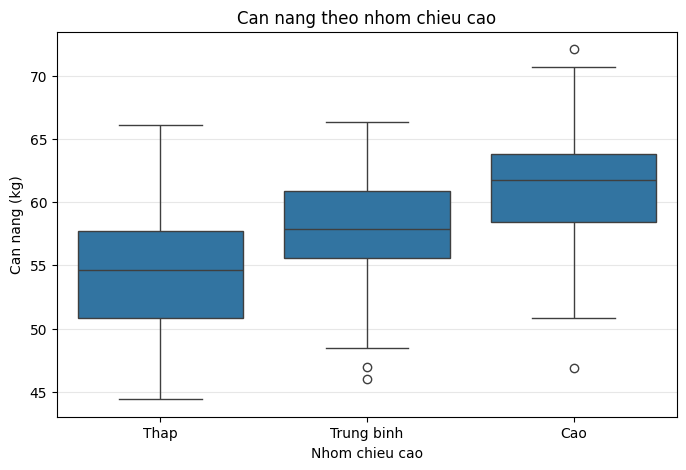


Da luu bieu do boxplot vao box.png


In [9]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = (
    pd.read_csv("200heightsweights.csv")
    .rename(columns={
        "Height(Inches)": "Height_in",
        "Weight(Pounds)": "Weight_lb"
    })
    .assign(
        Height_cm=lambda d: d["Height_in"] * 2.54,
        Weight_kg=lambda d: d["Weight_lb"] * 0.45359237
    )
    .assign(
        Height_cm=lambda d: d["Height_cm"].fillna(
            d["Height_cm"].mean()
        ),
        Weight_kg=lambda d: d["Weight_kg"].fillna(
            d["Weight_kg"].mean()
        )
    )
    .assign(
        BMI=lambda d: d["Weight_kg"] / (d["Height_cm"] / 100)**2
    )
)
print("Dữ liệu sau khi xử lý:")
print(df.head())

so_nguoi_gay = (df["BMI"] < 18.5).sum()

print("\nSố người có BMI < 18.5:", so_nguoi_gay)

df["Nhom_chieu_cao"] = pd.cut(
    df["Height_cm"],
    bins=[-np.inf, 170, 175, np.inf],
    labels=["Thap", "Trung binh", "Cao"],
    right=False
)
dem_nhom = df["Nhom_chieu_cao"].value_counts(
    sort=False
)
print("\nSố người theo nhóm chiều cao:")
print(dem_nhom)

ti_le = (
    df.assign(
        BMI_thap=df["BMI"] < 18.5
    )
    .groupby("Nhom_chieu_cao", observed=False)["BMI_thap"]
    .mean()
)

print("\nTỉ lệ người có BMI < 18.5 theo nhóm:")
print(ti_le)

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Nhom_chieu_cao",
    y="Weight_kg"
)
plt.title("Can nang theo nhom chieu cao")
plt.xlabel("Nhom chieu cao")
plt.ylabel("Can nang (kg)")
plt.grid(axis="y", alpha=0.3)
plt.savefig("box.png", dpi=300, bbox_inches="tight")
plt.show()
print("\nDa luu bieu do boxplot vao box.png")

try:
    import plotly.express as px

    fig = px.scatter(
        df,
        x="Height_cm",
        y="Weight_kg",
        color="Nhom_chieu_cao",
        title="Moi quan he giua chieu cao va can nang",
        labels={
            "Height_cm": "Chieu cao (cm)",
            "Weight_kg": "Can nang (kg)",
            "Nhom_chieu_cao": "Nhom chieu cao"
        },
        hover_data=["BMI"]
    )

    fig.show()

except ImportError:
    print("\nChua cai dat Plotly. Bo qua bieu do tuong tac.")
    print("Cai dat bang lenh: pip install plotly")


TH 6.4.
Với data/core_HRdata.csv (nhân sự; các cột Department, Sex, Pay Rate, Date of Hire, Performance Score): (1) làm sạch tên phòng ban bằng .str.strip() (còn 6 phòng ban); (2) lập bảng lương trung bình theo phòng ban (hàng) và giới tính (cột) bằng groupby và unstack; (3) chuyển Date of Hire sang kiểu thời gian, tính Tham_nien (số năm nguyên đến mốc 01/01/2017, dùng .dt.days // 365) và in 5 nhân viên có thâm niên cao nhất (sắp theo thâm niên giảm dần, ngang nhau thì theo tên nhân viên tăng dần, bằng sort_values với hai khoá); (4) thống kê số nhân viên theo Performance Score.

In [10]:
import pandas as pd

df = pd.read_csv("core_HRdata.csv")
df["Department"] = df["Department"].str.strip()
print("Danh sách phòng ban:")
print(df["Department"].unique())
print("\nSố phòng ban:", df["Department"].nunique())

bang_luong = (
    df.groupby(["Department", "Sex"])["Pay Rate"]
    .mean()
    .unstack()
)
print("\nBảng lương trung bình theo phòng ban và giới tính:")
print(bang_luong)

df["Date of Hire"] = pd.to_datetime(df["Date of Hire"])
moc_thoi_gian = pd.Timestamp("2017-01-01")
df["Tham_nien"] = (
    (moc_thoi_gian - df["Date of Hire"]).dt.days // 365
)
top_5 = df.sort_values(
    by=["Tham_nien", "Employee Name"],
    ascending=[False, True]
).head(5)
print("\n5 nhân viên có thâm niên cao nhất:")
print(top_5[["Employee Name", "Department",
             "Date of Hire", "Tham_nien"]])

thong_ke = df["Performance Score"].value_counts()
print("\nSố nhân viên theo Performance Score:")
print(thong_ke)


Danh sách phòng ban:
['Admin Offices' 'Executive Office' 'IT/IS' 'Production' 'Sales'
 'Software Engineering']

Số phòng ban: 6

Bảng lương trung bình theo phòng ban và giới tính:
Sex                      Female       Male
Department                                
Admin Offices         26.160000  40.500000
Executive Office      80.000000        NaN
IT/IS                 42.536316  46.740455
Production            22.613701  23.827284
Sales                 55.683333  55.375000
Software Engineering  52.330000  43.167500

5 nhân viên có thâm niên cao nhất:
        Employee Name     Department Date of Hire  Tham_nien
282  Riordan, Michael          Sales   2006-01-09         10
165       Pitt, Brad      Production   2007-11-05          9
254  Thibaud, Kenneth     Production   2007-06-25          9
68       Alagbe,Trina     Production   2008-01-07          8
0          Brown, Mia  Admin Offices   2008-10-27          8

Số nhân viên theo Performance Score:
Performance Score
Fully Meets       